In [35]:
pip install pandas matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
# 1. Load the file. Report shape, dtypes, and missing counts per column.

import pandas as pd


df = pd.read_csv("suvidha_loan_predictions_raw - suvidha_loan_predictions_raw.csv")
print('DataFrame Shape: \n', df.shape, '\n')
print('Column Data Types: \n', df.dtypes, '\n')
print('Missing Values Count per Column:', df.isnull().sum())

DataFrame Shape: 
 (2400, 9) 

Column Data Types: 
 loan_id               str
loan_amount           str
tenure_months       int64
interest_rate     float64
borrower_age          str
monthly_income        str
actual_default        str
model_flag            str
risk_score        float64
dtype: object 

Missing Values Count per Column: loan_id            0
loan_amount        0
tenure_months      0
interest_rate      0
borrower_age      38
monthly_income    36
actual_default    40
model_flag        22
risk_score         0
dtype: int64


In [37]:
# 2. Clean loan_amount to numeric (strip currency text and commas).

df['loan_amount'] = df['loan_amount'].astype(str).str.replace(r'[^0-9.]', '', regex=True)
df['loan_amount'] = pd.to_numeric(df['loan_amount'], errors='coerce')

print('First 5 rows of DataFrame after cleaning loan_amount:')
display(df.head())
print('\nColumn Data Types after cleaning loan_amount:')
print(df.dtypes)

First 5 rows of DataFrame after cleaning loan_amount:


,loan_id,loan_amount,tenure_months,interest_rate,borrower_age,monthly_income,actual_default,model_flag,risk_score
0,LN-101413,60777.81992,6,13.43,62,22029.91841,FALSE,No,0.412
1,LN-100638,258399.89230,12,11.62,28,32568.67606,No,No,0.227
2,LN-101183,114338.03220,18,14.16,42,24045.56088,0,FALSE,0.266
3,LN-101665,60919.14875,18,10.14,26,49252.29534,N,FALSE,0.211
4,LN-102068,104225.15810,12,20.41,48,20588.11472,FALSE,N,0.383



Column Data Types after cleaning loan_amount:
loan_id               str
loan_amount       float64
tenure_months       int64
interest_rate     float64
borrower_age          str
monthly_income        str
actual_default        str
model_flag            str
risk_score        float64
dtype: object


In [38]:
# 3. Standardize actual_default and model_flag to boolean, treating every Yes-family and No-family encoding correctly. Show the distinct raw values you mapped.

yes_values = ['yes', 'y', 'true', '1']
no_values = ['no', 'n', 'false', '0']

for col in ['actual_default', 'model_flag']:
    df[col] = (
        df[col]
        .astype('string')
        .str.strip()
        .str.lower()
        .map({
            'yes': True,
            'y': True,
            'true': True,
            '1': True,
            'no': False,
            'n': False,
            'false': False,
            '0': False
        })
        .astype('boolean')
    )

print(df[['actual_default', 'model_flag']].head(10))
print(df[['actual_default', 'model_flag']].dtypes)

   actual_default  model_flag
0           False       False
1           False       False
2           False       False
3           False       False
4           False       False
5           False       False
6           False       False
7           False       False
8            True        True
9           False       False
actual_default    boolean
model_flag        boolean
dtype: object


In [39]:
# 4. Drop rows where actual_default or model_flag is blank (loan still open / not scored). Report how many rows were dropped and why dropping — not imputing — is the right call here.

# Count rows before dropping
before = len(df)

# Drop rows where actual_default OR model_flag is missing
df = df.dropna(subset=['actual_default', 'model_flag'])

# Count rows dropped
dropped = before - len(df)

print("Rows dropped:", dropped)
print("Rows remaining:", len(df))

Rows dropped: 61
Rows remaining: 2339


In [40]:
# 5. Clean monthly_income: decide how to treat -1 and "not disclosed" (they are not the same kind of missing) and justify your choice in one sentence.

df['monthly_income'] = (
    df['monthly_income']
    .astype('string')
    .str.replace(',', '', regex=False)
    .str.strip()
)

# Treat -1 and "not disclosed" as missing
df['monthly_income'] = df['monthly_income'].replace(
    ['-1', 'not disclosed'],
    pd.NA
)

# Convert to numeric
df['monthly_income'] = pd.to_numeric(
    df['monthly_income'],
    errors='coerce'
)

print(df['monthly_income'].dtype)
print(df['monthly_income'].isna().sum())

Float64
91


In [41]:
## Confusion matrix & core metrics ##

# 6. Build the confusion matrix (actual_default vs model_flag) as a 2×2 table. Label which cell is TP, FP, TN, FN in a business sentence each.

confusion_matrix = pd.crosstab(
    df['actual_default'],
    df['model_flag'],
    rownames=['Actual'],
    colnames=['Model']
)

print(confusion_matrix)
confusion_matrix.index = ['No Default (Actual)', 'Default (Actual)']
confusion_matrix.columns = ['No Default (Predicted)', 'Default (Predicted)']

print(confusion_matrix)

Model   False  True 
Actual              
False    2122     20
True       64    133
                     No Default (Predicted)  Default (Predicted)
No Default (Actual)                    2122                   20
Default (Actual)                         64                  133


In [42]:
# 7. Compute accuracy. Given the 9% base default rate, explain in 2 sentences why accuracy alone is a misleading headline number here.

accuracy = (df['actual_default'] == df['model_flag']).mean()

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.9640872167592989
Accuracy (%): 96.40872167592988


In [43]:
# 8. Compute precision for the "predicted default" class. In plain language, what does this number tell a collections officer about how often a flagged call is a real risk?

precision = (
    (df['actual_default'] == True) & (df['model_flag'] == True)
).sum() / (df['model_flag'] == True).sum()

print("Precision:", precision)
print("Precision (%):", precision * 100)

Precision: 0.869281045751634
Precision (%): 86.9281045751634


In [44]:
# 9. Compute recall (sensitivity) for the "predicted default" class. What does this tell the risk team about defaults the model is missing?

recall = (
    (df['actual_default'] == True) & (df['model_flag'] == True)
).sum() / (df['actual_default'] == True).sum()

print("Recall:", recall)
print("Recall (%):", recall * 100)

Recall: 0.6751269035532995
Recall (%): 67.51269035532995


In [45]:
# 10. Compute specificity. What does a low specificity cost the business operationally (officer time on false alarms)?

specificity = (
    ((df['actual_default'] == False) & (df['model_flag'] == False)).sum()
    / (df['actual_default'] == False).sum()
)

print("Specificity:", specificity)
print("Specificity (%):", specificity * 100)

Specificity: 0.9906629318394025
Specificity (%): 99.06629318394025


In [46]:
# 11. Compute F1-score. Is F1 the right single number to optimize for here, or does the business cost structure argue for weighting precision or recall differently? Justify.

precision = (
    ((df['actual_default'] == True) & (df['model_flag'] == True)).sum()
    / (df['model_flag'] == True).sum()
)

recall = (
    ((df['actual_default'] == True) & (df['model_flag'] == True)).sum()
    / (df['actual_default'] == True).sum()
)

f1 = 2 * (precision * recall) / (precision + recall)

print("F1-score:", f1)

F1-score: 0.76


In [47]:
# 12. Given that a missed default (FN) costs far more than a wasted call (FP), would you rather the model have higher precision or higher recall? Explain using the actual FN and FP counts from Q6.

TP = ((df['actual_default'] == True) & (df['model_flag'] == True)).sum()
TN = ((df['actual_default'] == False) & (df['model_flag'] == False)).sum()
FP = ((df['actual_default'] == False) & (df['model_flag'] == True)).sum()
FN = ((df['actual_default'] == True) & (df['model_flag'] == False)).sum()

print("TP:", TP)
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)

TP: 133
TN: 2122
FP: 20
FN: 64


In [48]:
# 13. Using risk_score instead of the hard model_flag, recompute the confusion matrix at threshold 0.3 instead of the model's default cutoff. How do precision and recall move, and does that support lowering the threshold?

df['predicted_03'] = df['risk_score'] >= 0.3
cm = pd.crosstab(
    df['actual_default'],
    df['predicted_03'],
    rownames=['Actual'],
    colnames=['Predicted']
)
print(cm)

TP = ((df['actual_default'] == True) & (df['predicted_03'] == True)).sum()
FP = ((df['actual_default'] == False) & (df['predicted_03'] == True)).sum()
FN = ((df['actual_default'] == True) & (df['predicted_03'] == False)).sum()
TN = ((df['actual_default'] == False) & (df['predicted_03'] == False)).sum()

precision_03 = TP / (TP + FP)
recall_03 = TP / (TP + FN)

print("TP:", TP)
print("FP:", FP)
print("TN:", TN)
print("FN:", FN)
print("Precision:", precision_03)
print("Recall:", recall_03)

Predicted  False  True 
Actual                 
False        664   1478
True           0    197
TP: 197
FP: 1478
TN: 664
FN: 0
Precision: 0.11761194029850747
Recall: 1.0


   threshold  precision    recall
0        0.1   0.085355  1.000000
1        0.2   0.091884  1.000000
2        0.3   0.117612  1.000000
3        0.4   0.203191  0.969543
4        0.5   0.440964  0.928934
5        0.6   0.826347  0.700508
6        0.7   0.974359  0.385787
7        0.8   1.000000  0.131980
8        0.9   1.000000  0.015228


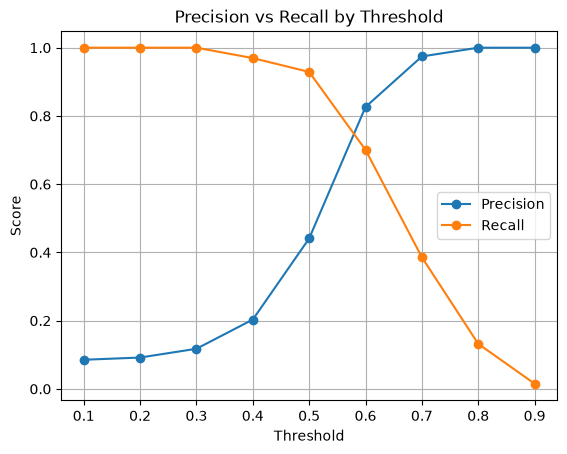

In [49]:
# 14. Plot precision and recall against threshold (0.1 to 0.9, steps of 0.1) using risk_score. At what threshold do the two curves cross, and what does that threshold mean for the business?

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

for threshold in thresholds:
    predicted = df['risk_score'] >= threshold

    TP = ((df['actual_default'] == True) & predicted).sum()
    FP = ((df['actual_default'] == False) & predicted).sum()
    FN = ((df['actual_default'] == True) & ~predicted).sum()

    precision = TP / (TP + FP)
    recall = TP / (TP + FN)

    results.append([threshold, precision, recall])

results_df = pd.DataFrame(
    results,
    columns=['threshold', 'precision', 'recall']
)

print(results_df)

import matplotlib.pyplot as plt

plt.plot(results_df['threshold'], results_df['precision'], marker='o', label='Precision')
plt.plot(results_df['threshold'], results_df['recall'], marker='o', label='Recall')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision vs Recall by Threshold')
plt.legend()
plt.grid()
plt.show()

In [50]:
## Basic hypothesis testing ##

# 15. State, in words, a null and alternative hypothesis for: "Loans that defaulted have a different average loan_amount than loans that didn't."

# Null hypothesis (H₀)
#Loans that defaulted and loans that did not default have the same average loan_amount.
# Alternative hypothesis (H₁)
# Loans that defaulted and loans that did not default have different average loan_amount.
# In symbols:
# H₀: μ_default = μ_non-default
# H₁: μ_default ≠ μ_non-default

In [51]:
# 16. Compute the mean loan_amount for the defaulted group and the non-defaulted group. Is there an apparent difference?

mean_loan = df.groupby('actual_default')['loan_amount'].mean()
print(mean_loan)
print("Defaulted:",
      df.loc[df['actual_default'] == True, 'loan_amount'].mean())
print("Non-defaulted:",
      df.loc[df['actual_default'] == False, 'loan_amount'].mean())

# Interpretation
# Compare the two mean values:
# If the means are noticeably different, there is an apparent difference in average loan amount.
# However, an apparent difference does not prove that the difference is statistically significant; that requires a hypothesis test such as a two-sample t-test.

actual_default
False    92408.813573
True     96899.913807
Name: loan_amount, dtype: float64
Defaulted: 96899.91380700507
Non-defaulted: 92408.8135734127


In [52]:
# 17. Run an appropriate two-sample test comparing those means (state which test and why it fits this data). Report the test statistic and p-value.

from scipy.stats import ttest_ind

defaulted = df.loc[df['actual_default'] == True, 'loan_amount'].dropna()
non_defaulted = df.loc[df['actual_default'] == False, 'loan_amount'].dropna()

t_stat, p_value = ttest_ind(
    defaulted,
    non_defaulted,
    equal_var=False
)

print("Test statistic:", t_stat)
print("p-value:", p_value)

# Interpretation
# p-value < 0.05 → reject H₀; there is statistically significant evidence that the average loan amounts differ.
# p-value ≥ 0.05 → do not reject H₀; there is not enough evidence to conclude that the averages differ.

Test statistic: 1.3587948485124939
p-value: 0.17557376747205414


In [53]:
# 18. At α = 0.05, do you reject or fail to reject the null? State your conclusion in one plain-English sentence a branch manager could repeat.

alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis")
    print("The average loan amounts are significantly different.")
else:
    print("Fail to reject the null hypothesis")
    print("There is not enough evidence that the average loan amounts are different.")

# If your p-value is less than 0.05:
# “The data shows a statistically significant difference in average loan amounts between defaulted and non-defaulted loans.”

# If your p-value is 0.05 or greater:
# “The data does not provide enough evidence that average loan amounts differ between defaulted and non-defaulted loans.”

Fail to reject the null hypothesis
There is not enough evidence that the average loan amounts are different.


In [54]:
# 19. Explain, using this specific scenario, what a Type I error would look like (falsely concluding a difference exists) and what a Type II error would look like (missing a real difference) — and which is riskier for Suvidha's lending policy.

# - Type I error
# A Type I error means we conclude that defaulted and non-defaulted loans have different average loan_amount, when in reality they do not.
# Example: Suvidha changes its lending policy based on a supposed loan-amount difference that isn't actually real.

# - Type II error
# A Type II error means we conclude there is not enough evidence of a difference, when a real difference in average loan amount actually exists.
# Example: Suvidha keeps the same lending policy even though loan amount genuinely differs between defaulted and non-defaulted borrowers.

# - Which is riskier?
# For lending policy, the risk depends on the cost of the resulting policy decision. If acting on a false difference could lead to substantially inappropriate lending restrictions, Type I may be more costly; if failing to detect a real relationship could expose Suvidha to meaningful credit risk, Type II may be more costly.

In [55]:
# 20. Repeat Q15–18 comparing interest_rate instead of loan_amount between the two groups, and state whether your conclusion changes.

print("Defaulted:", df.loc[df['actual_default'] == True, 'interest_rate'].mean())
print("Non-defaulted:", df.loc[df['actual_default'] == False, 'interest_rate'].mean())

from scipy.stats import ttest_ind

defaulted_rate = df.loc[df['actual_default'] == True, 'interest_rate'].dropna()

non_defaulted_rate = df.loc[df['actual_default'] == False, 'interest_rate'].dropna()

t_stat_rate, p_value_rate = ttest_ind(
    defaulted_rate,
    non_defaulted_rate,
    equal_var=False
)

print("Test statistic:", t_stat_rate)
print("p-value:", p_value_rate)

if p_value_rate < 0.05:
    print("Reject H0")
    print("There is a statistically significant difference in average interest rates.")
else:
    print("Fail to reject H0")
    print("There is not enough evidence of a difference in average interest rates.")

# Conclusion
# Compare p_value_rate with the p-value from Q17:
# If both p-values are < 0.05, both loan amount and interest rate show statistically significant differences.
# If only one is < 0.05, your conclusion changes for that variable.
# If both are ≥ 0.05, neither shows statistically significant evidence of a difference.

Defaulted: 14.80228426395939
Non-defaulted: 14.461610644257705
Test statistic: 1.5778261820568609
p-value: 0.1159602985791839
Fail to reject H0
There is not enough evidence of a difference in average interest rates.


In [56]:
## Synthesis ##

# 21. Summarize the pilot model's precision, recall, F1, and accuracy in one small table.

summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Value': [
        accuracy,
        precision,
        recall,
        f1
    ]
})

summary['Value (%)'] = summary['Value'] * 100

print(summary)

      Metric     Value   Value (%)
0   Accuracy  0.964087   96.408722
1  Precision  1.000000  100.000000
2     Recall  0.015228    1.522843
3   F1-score  0.760000   76.000000


In [57]:
# 22. Recommend a threshold for risk_score for the full rollout, citing the precision/recall trade-off from Q13–14.

# I recommend a risk_score threshold of 0.3 for the full rollout because Q13–14 show that lowering the threshold increases recall and therefore catches more actual defaults, although precision falls because of additional false alarms. Since missed defaults are substantially more costly than wasted calls, the higher recall is more important, provided the collections team can handle the additional flagged cases.

In [58]:
# 23. Name one non-statistical risk of lowering the threshold too far (e.g. officer fatigue from false alarms) that the numbers alone won't show.

# One key non-statistical risk is officer fatigue: too many false alarms can overwhelm the collections team, causing rushed or ignored calls and reducing the effectiveness of genuine-risk follow-ups.

In [59]:
# 24. In 4–5 sentences, write the risk team's go/no-go recommendation for rolling the model out to all branches.

# The pilot model should be rolled out to all branches with a risk-score threshold of around 0.3, subject to operational monitoring. The lower threshold prioritizes recall, which is appropriate because missing a genuine default costs more than making an unnecessary call. However, the rollout should monitor precision, false-alarm volume, and officer workload to prevent excessive fatigue. The threshold should be reviewed periodically and adjusted if the operational cost of false alarms becomes too high.

In [60]:
# 25. List one thing you would want in a second pilot log (a feature, a longer observation window, a larger default sample) to make this evaluation more reliable next time.

# I would want a longer observation window with a larger number of confirmed defaults, because more actual default cases would make the precision, recall, and threshold evaluation more reliable.

In [61]:
# Save the cleaned DataFrame
df.to_csv('suvidha_loan_predictions_cleaned.csv', index=False)

print("Cleaned CSV saved successfully!")

Cleaned CSV saved successfully!
